Fig 1: comparison between trajectories of different tumor growth curves

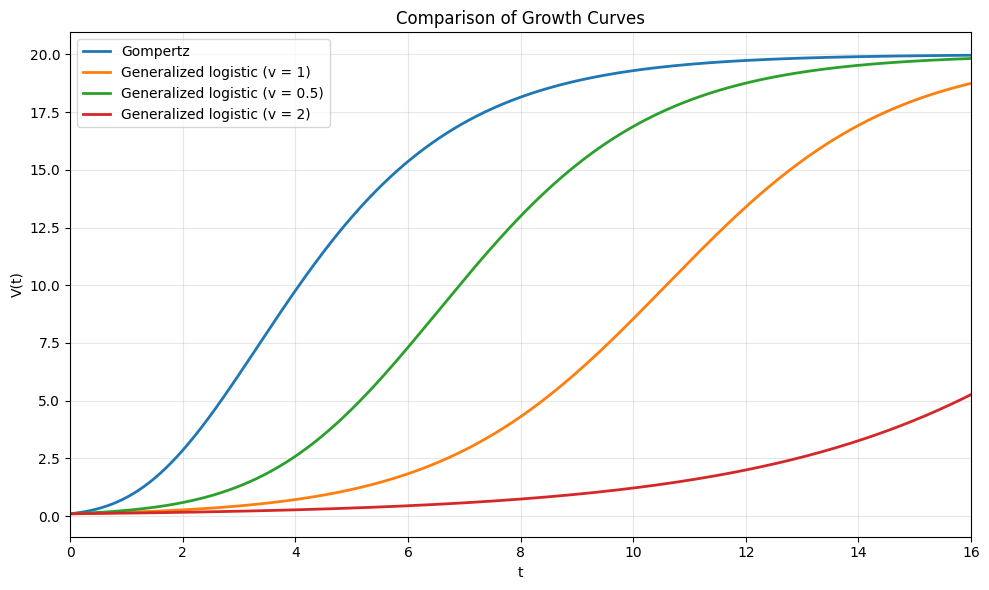

In [6]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# General settings
maxSize = 20
initialSize = 0.1
rate = 0.5

tMin = 0
tMax = 16

# SymPy symbol
t = sp.symbols('t')

# Numerical t values for plotting
t_values = np.linspace(tMin, tMax, 500)

# Gompertzian curve
V_Gompertz = maxSize * np.exp(
    np.log(initialSize / maxSize) * np.exp(-rate * t_values)
)

# Generalized logistic (v = 1)
v = 1
C = (maxSize/initialSize) ** v - 1
V_gen1 = maxSize / (
    1 + C * np.exp(-rate * t_values)
)

# Generalized logistic (v = 0.5)
v = 0.5
C = (maxSize/initialSize) ** v - 1
V_gen05 = maxSize / (
    1 + C * np.exp(-rate * t_values)
) ** (1/v)

# Generalized logistic (v = 2)
v = 2
C = (maxSize/initialSize) ** v - 1
V_gen2 = maxSize / (
    1 + C * np.exp(-rate * t_values)
) ** (1/v)


# Plot
plt.figure(figsize=(10, 6))

plt.plot(
    t_values,
    V_Gompertz,
    label="Gompertz",
    linewidth=2
)

plt.plot(
    t_values,
    V_gen1,
    label="Generalized logistic (v = 1)",
    linewidth=2
)

plt.plot(
    t_values,
    V_gen05,
    label="Generalized logistic (v = 0.5)",
    linewidth=2
)

plt.plot(
    t_values,
    V_gen2,
    label="Generalized logistic (v = 2)",
    linewidth=2
)

plt.xlabel("t")
plt.ylabel("V(t)")
plt.title("Comparison of Growth Curves")

plt.xlim(tMin, tMax)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()

Fig 2: initial condition can determine if a candidate pass the forward-positivity filter

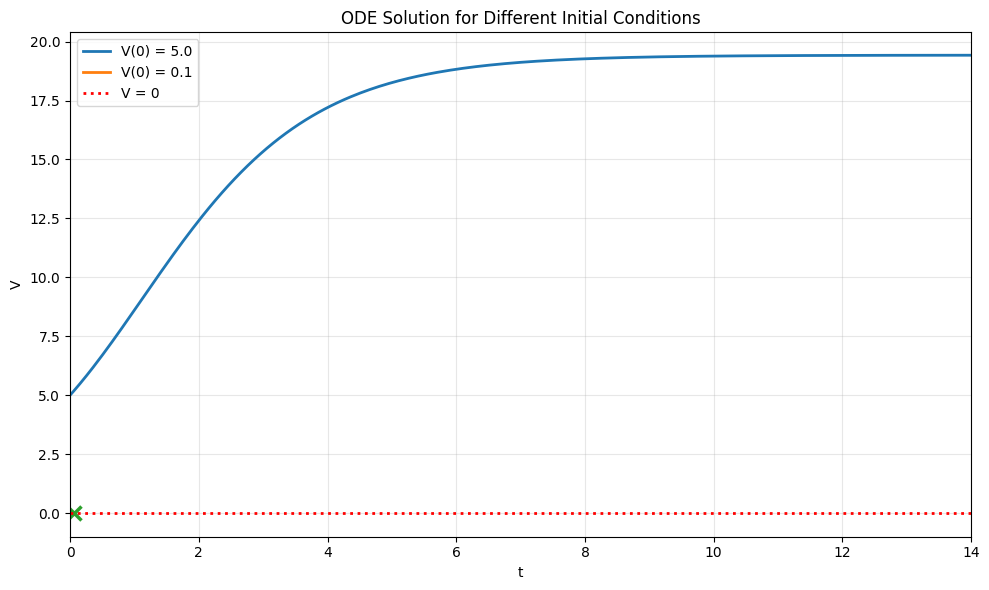

In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Solve the following ODE with different initial conditions

V = sp.symbols('V')

expr = -V * (sp.log(V + 5.912802) - 3.3113704) - 1.5374633

# Initial conditions
initialCond1 = 5.0
initialCond2 = 0.1

tMin = 0
tMax = 14


# Convert SymPy expression into a numerical function
expr_func = sp.lambdify(V, expr, modules="numpy")



# Event: stop integration when V = 0
def hit_zero(t, y):
    return y[0]

# Stop the solver when V crosses zero
hit_zero.terminal = True

# Detect crossing from positive V to negative V
hit_zero.direction = -1



# Numerical ODE function
def ode_func(t, y):
    V_value = y[0]

    # The logarithm requires V + 5.912802 > 0.
    # This check prevents invalid values from propagating.
    if V_value + 5.912802 <= 0:
        return [0.0]

    return [expr_func(V_value)]



# Solve for both initial conditions
solutions = []

for initial_cond in [initialCond1, initialCond2]:

    sol = solve_ivp(
        ode_func,
        (tMin, tMax),
        [initial_cond],
        events=hit_zero,
        dense_output=True,
        max_step=0.05,
        rtol=1e-9,
        atol=1e-11
    )

    solutions.append(sol)


# Plotting section
fig, ax = plt.subplots(figsize=(10, 6))

labels = [
    f"V(0) = {initialCond1}",
    f"V(0) = {initialCond2}"
]

colors = [None, None]

for sol, label in zip(solutions, labels):

    # Solver-generated points
    t_values = sol.t
    V_values = sol.y[0]

    ax.plot(
        t_values,
        V_values,
        linewidth=2,
        label=label
    )

    # Check whether V = 0 was reached
    if len(sol.t_events[0]) > 0:

        # Time at which V reaches zero
        t_zero = sol.t_events[0][0]

        # Mark the intersection with a cross
        ax.plot(
            t_zero,
            0,
            marker="x",
            markersize=10,
            markeredgewidth=2.5,
            linestyle="none"
        )


# V = 0 axis
ax.axhline(
    0,
    linestyle=":",
    color="red",
    linewidth=2,
    label="V = 0"
)

ax.set_xlim(tMin, tMax)

# Start vertical axis at -1
ax.set_ylim(bottom=-1)

ax.set_xlabel("t")
ax.set_ylabel("V")
ax.set_title("ODE Solution for Different Initial Conditions")

ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Fig 3: Sanity check of Spine -> PySR -> PINN framework with dense and noiseless data

c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
[ Info: Started!
[ Info: Final population:
[ Info: Results saved to:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.569e+00  0.000e+00  y = 1.4082
5           1.569e+00  1.192e-07  y = x₀ - (x₀ - 1.4082)
6           1.040e+00  4.113e-01  y = (x₀ * -0.10492) + 2.8331
8           1.040e+00  1.192e-07  y = (x₀ * 0.89509) + (2.833 - x₀)
11          1.597e-01  6.246e-01  y = (x₀ * 0.057981) ^ (x₀ * -0.21749)
16          8.857e-11  4.263e+00  y = (x₀ - ((x₀ + -1.4979) - (log(x₀) * -0.5))) * x₀
───────────────────────────────────────────────────────────────────────────────────────────────────
  - outputs\20260920_114759_p6hmYH\hall_of_fame.csv
Best PySR Expression: x0*(1.4978675 - 0.5000005*log(x0))
Best expression after PINN refit: x0*(1.49782044546945 - 0.500044618334089*log(x0))


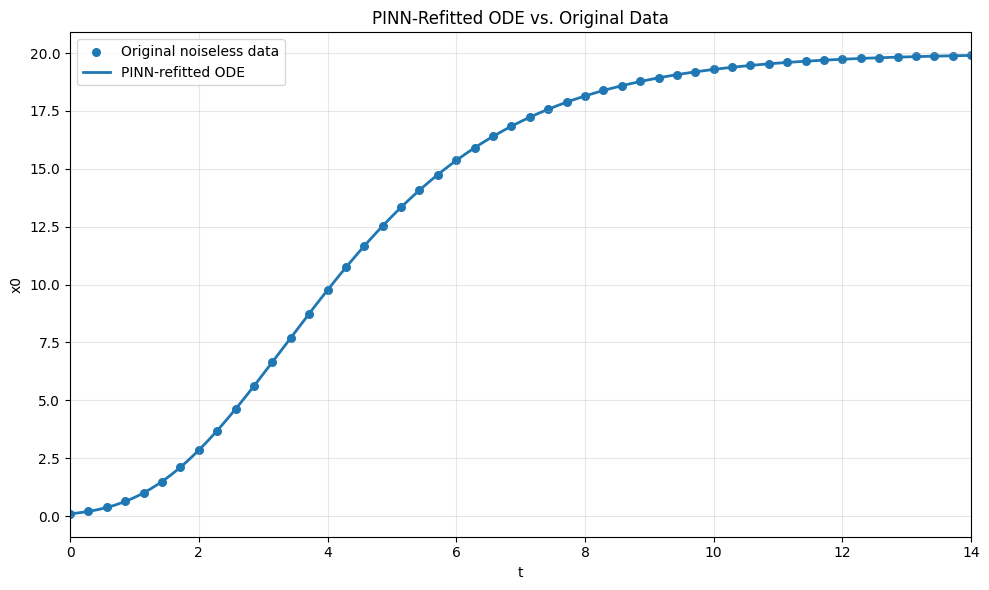

In [3]:
import SR_Wrapper as wp
import pinn_update as pinn
import tumorData as td
import auxilary_func as af

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


maxSize = 20
initialSize = 0.1
rate = 0.5
nPoints = 50

# Dense noiseless data generation
V_clean, t_clean = td.tumor_data(
    maxSize,
    rate,
    initialSize,
    0,
    14,
    nPoints,
    0,
    'G'
)

# Spline refit
V_smooth, dV_smooth = af.fit_relationship_spline(
    t_clean,
    V_clean,
    plot=False,
    min_k=5,
    restricted_s=0
)



# PySR law recovery
sr_wrapper = wp.PySRWrapper(random_state=77)
sr_wrapper.fit(V_smooth, dV_smooth)

best_expr = sr_wrapper.get_best_expression()
print(f"Best PySR Expression: {best_expr}")

# PINN law refit
learnable_params, symbolic_expr_str, constant_names = pinn.extract_constants(
    str(best_expr)
)

initial_param_values = {
    name: info["value"]
    for name, info in learnable_params.items()
}

(
    domain_min_func,
    domain_max_func,
    domain_str,
    has_constraint,
    domain_type,
) = pinn.extract_domain_function(
    str(best_expr),
    param_names=constant_names,
    param_values=initial_param_values,
    verbose=False,
)

(
    net,
    params,
    history,
    training_status,
    restored_expr,
) = pinn.train_pinn(
    VolArr=V_clean,
    tArr=t_clean,
    simplified_expr=str(best_expr),
    domain_min_func=domain_min_func,
    domain_max_func=domain_max_func,
    domain_type=domain_type,
    lambda_phys=0.1,
    num_epochs=500,
    lr_net=1e-2,
    lr_params=1e-5,
    plot_results=False,
    verbose=False,
    physics_points=1000,
)

pinn_expr_str = str(restored_expr)
print(f"Best expression after PINN refit: {pinn_expr_str}")
pinn_expr = sp.sympify(pinn_expr_str)



# Solve the PINN-refitted ODE
# x0 is the state variable
x0 = sp.Symbol("x0")

# Convert the symbolic ODE RHS into a numerical function
pinn_func = sp.lambdify(
    x0,
    pinn_expr,
    modules="numpy"
)


def ode_func(t, y):
    """
    Numerical form of

        dx0/dt = pinn_expr(x0)
    """

    x0_value = y[0]

    result = pinn_func(x0_value)

    return [float(np.asarray(result))]


# Directly use initialSize as x0(0)
x0_initial = float(initialSize)


# Solve from t = 0 to t = 14
sol = solve_ivp(
    ode_func,
    (0.0, 14.0),
    [x0_initial],
    t_eval=np.linspace(0.0, 14.0, 500),
    rtol=1e-9,
    atol=1e-11,
    max_step=0.05,
)

# Plot PINN ODE solution against original data
plt.figure(figsize=(10, 6))

# Plot all original (t, V) data points as ONE dataset
plt.scatter(
    t_clean,
    V_clean,
    s=30,
    label="Original noiseless data"
)

# Plot the PINN-refitted ODE solution as a continuous curve
plt.plot(
    sol.t,
    sol.y[0],
    linewidth=2,
    label="PINN-refitted ODE"
)

plt.xlabel("t")
plt.ylabel("x0")
plt.title("PINN-Refitted ODE vs. Original Data")

plt.xlim(0, 14)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Fig 4: Phase-space ranking problem under sparse noisy data

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
Compiling Julia backend...
[ Info: Started!



Expressions evaluated per second: 6.260e+04
Progress: 353 / 31000 total iterations (1.139%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.027e+00  0.000e+00  y = 1.8566
5           2.027e+00  2.980e-08  y = (x₀ + 1.8568) - x₀
6           1.418e+00  3.575e-01  y = log(21.13 - x₀)
9           1.405e+00  3.029e-03  y = log(21.287 - x₀) * 0.95107
11          5.091e-01  5.075e-01  y = (x₀ + ((0.72924 - x₀) * 1.0379)) * x₀
13          4.811e-01  2.831e-02  y = (x₀ * ((0.72924 - (x₀ * 1.0379)) + x₀)) + 0.40841
16          4.526e-01  2.034e-02  y = (((2.4941 - x₀) * -0.63848) + 2.1978) - ((x₀ * x₀) * 0...
                                      .033258)
17          4.526e-01  2.623e-06  y = (x₀ + ((((0.64697 - x₀) * 1.0333) + x₀) - x₀)) * (x₀ +...
                                       

[ Info: Final population:
[ Info: Results saved to:


───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.027e+00  0.000e+00  y = 1.8566
5           2.027e+00  1.490e-07  y = (x₀ + 1.8566) - x₀
6           1.418e+00  3.575e-01  y = log(21.13 - x₀)
8           1.418e+00  5.960e-08  y = log(21.127 - x₀) + 0.00098328
9           5.091e-01  1.024e+00  y = x₀ * ((x₀ * -0.03787) + 0.75683)
11          4.526e-01  5.882e-02  y = (x₀ - -0.90545) * ((x₀ * -0.033258) + 0.66859)
13          4.526e-01  5.126e-06  y = ((x₀ + (0.63832 - (x₀ * 1.0333))) * x₀) + 0.60608
14          4.387e-01  3.119e-02  y = (-0.39139 - (x₀ * (x₀ * -0.00098782))) * (-2.4044 - x₀...
                                      )
16          4.368e-01  2.123e-03  y = ((-13.997 - x₀) * (-0.45725 - ((x₀ * x₀) * -0.0007383)...
                                      )) + -5.5548
18          4.368e-01  3.457e-05  y = (((x₀ * (x₀ - ((x₀ * 1.0008) + 0.0099096))) + 0.45409)...
          

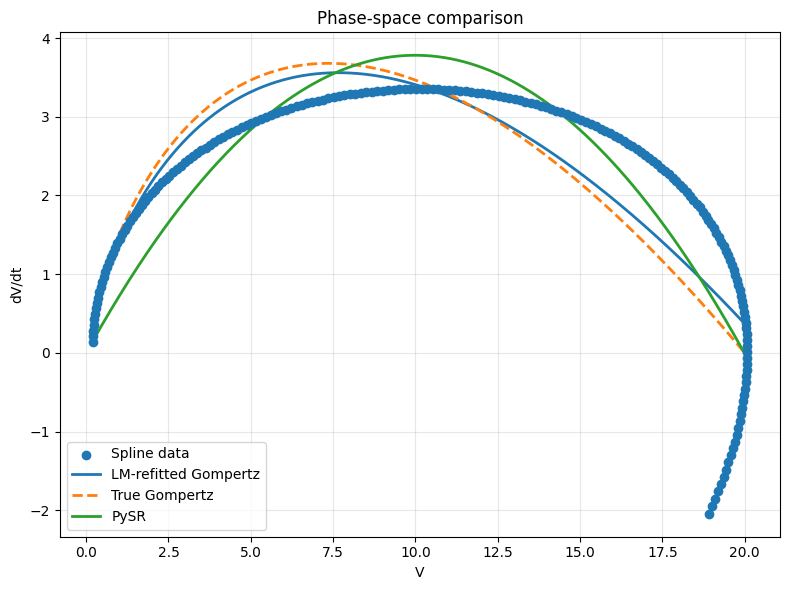

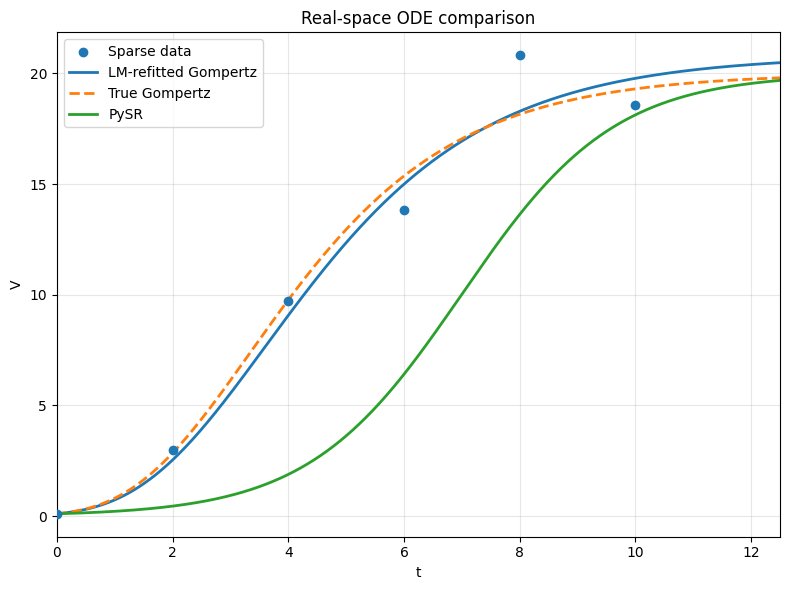

  - outputs\20260920_122636_dDZ93F\hall_of_fame.csv


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.integrate import solve_ivp

import SR_Wrapper as wp
import tumorData as td
import auxilary_func as af


# Settings
maxSize = 20
initialSize = 0.1
rate = 0.5
noise = 0.08
nPoints = 6

# True law
actual_ODE_str = f"{rate}*x0*log({maxSize}/x0)"

# Sparse noisy data generation
V_sparse, t = td.tumor_data(
    maxSize,
    rate,
    initialSize,
    0,
    10,
    nPoints,
    noise,
    'G'
)

# Spline refit
V_smooth, dV_smooth = af.fit_relationship_spline(
    t,
    V_sparse,
    plot=False
)

# PySR law recovery - best candidate
sr_wrapper = wp.PySRWrapper(random_state=77)
sr_wrapper.fit(V_smooth, dV_smooth)

best_expr = sr_wrapper.get_best_expression()
print(f"Best PySR Expression: {best_expr}")

# Gompertzian fit to smoothened data
def gompertz_rhs(V, rate_p, maxSize_p):
    """
    Gompertz RHS used for LM fitting.
    """
    return rate_p * V * np.log(maxSize_p / V)


# Initial parameter guess
p0 = [rate-0.1, maxSize-10]

# Levenberg-Marquardt fit
gompertz_params, gompertz_cov = curve_fit(
    gompertz_rhs,
    V_smooth,
    dV_smooth,
    p0=p0,
    method='lm'
)

rate_p, maxSize_p = gompertz_params

print("\nLM-refitted Gompertz parameters:")
print(f"rate_p    = {rate_p:.12g}")
print(f"maxSize_p = {maxSize_p:.12g}")

# Convert PySR expression into a callable function
x0 = sp.symbols("x0")

pysr_sympy_expr = sp.sympify(str(best_expr))

pysr_rhs_func = sp.lambdify(
    x0,
    pysr_sympy_expr,
    modules="numpy"
)

def pysr_rhs(V):
    """
    Numerical PySR RHS.

    The mathematical domain of the PySR expression must be
    respected during evaluation.
    """
    return np.asarray(pysr_rhs_func(V), dtype=float)


# Phase-space comparison

V_min = np.min(V_smooth)
V_max = np.max(V_smooth)

# Dense V axis for smooth curves
V_plot = np.linspace(V_min, V_max, 500)

# LM-refitted Gompertz
dV_gompertz = gompertz_rhs(
    V_plot,
    rate_p,
    maxSize_p
)

# PySR expression
dV_pysr = pysr_rhs(V_plot)

# Actual Gompertz ODE
dV_actual = rate * V_plot * np.log(maxSize / V_plot)

# Keep only finite PySR values for plotting
pysr_phase_valid = np.isfinite(dV_pysr)

plt.figure(figsize=(8, 6))

plt.scatter(
    V_smooth,
    dV_smooth,
    label="Spline data",
    zorder=3
)

plt.plot(
    V_plot,
    dV_gompertz,
    linewidth=2,
    label="LM-refitted Gompertz"
)

plt.plot(
    V_plot,
    dV_actual,
    linewidth=2,
    linestyle="--",
    label="True Gompertz"
)

plt.plot(
    V_plot[pysr_phase_valid],
    dV_pysr[pysr_phase_valid],
    linewidth=2,
    label="PySR"
)

plt.xlabel("V")
plt.ylabel("dV/dt")
plt.title("Phase-space comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Solve both ODEs from t = 0 to t = 12.5
t_start = 0.0
t_end = 12.5

# Dense output grid for plotting
t_plot = np.linspace(t_start, t_end, 1000)


# ---------- LM-refitted Gompertz ODE ----------

def gompertz_ode(t, y):
    V = y[0]

    # Avoid evaluating log at an invalid/non-positive state.
    # For the normal Gompertz trajectory this should not be
    # triggered, but it prevents NaNs from entering solve_ivp.
    if V <= 0 or maxSize_p <= 0:
        return [0.0]

    return [
        rate_p * V * np.log(maxSize_p / V)
    ]


sol_gompertz = solve_ivp(
    gompertz_ode,
    (t_start, t_end),
    [initialSize],
    t_eval=t_plot,
    rtol=1e-8,
    atol=1e-10
)


if not sol_gompertz.success:
    raise RuntimeError(
        f"Gompertz ODE solver failed: {sol_gompertz.message}"
    )

# ---------- Actual Gompertz ODE ----------

def actual_ode(t, y):
    V = y[0]

    if V <= 0:
        return [0.0]

    return [
        rate * V * np.log(maxSize / V)
    ]


sol_actual = solve_ivp(
    actual_ode,
    (t_start, t_end),
    [initialSize],
    t_eval=t_plot,
    rtol=1e-8,
    atol=1e-10
)


if not sol_actual.success:
    raise RuntimeError(
        f"Actual ODE solver failed: {sol_actual.message}"
    )

def pysr_ode(t, y):
    V = y[0]

    # Prevent invalid values from propagating through
    # expressions containing logarithms, divisions, etc.
    if not np.isfinite(V) or V <= 0:
        return [0.0]

    try:
        value = float(pysr_rhs_func(V))
    except (ValueError, FloatingPointError, OverflowError):
        return [0.0]

    if not np.isfinite(value):
        return [0.0]

    return [value]


sol_pysr = solve_ivp(
    pysr_ode,
    (t_start, t_end),
    [initialSize],
    t_eval=t_plot,
    rtol=1e-8,
    atol=1e-10
)


if not sol_pysr.success:
    raise RuntimeError(
        f"PySR ODE solver failed: {sol_pysr.message}"
    )


# Real-space comparison
plt.figure(figsize=(8, 6))

# Original sparse noisy observations
plt.scatter(
    t,
    V_sparse,
    label="Sparse data",
    zorder=3
)

# LM-refitted Gompertz solution
plt.plot(
    sol_gompertz.t,
    sol_gompertz.y[0],
    linewidth=2,
    label="LM-refitted Gompertz"
)

# Actual Gompertz solution
plt.plot(
    sol_actual.t,
    sol_actual.y[0],
    linewidth=2,
    linestyle="--",
    label="True Gompertz"
)

# PySR ODE solution
plt.plot(
    sol_pysr.t,
    sol_pysr.y[0],
    linewidth=2,
    label="PySR"
)

plt.xlabel("t")
plt.ylabel("V")
plt.title("Real-space ODE comparison")
plt.xlim(t_start, t_end)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Fig 5: Gompertz (mis)fit on logistic curve

Number of data points: 12
t range: 0.00 to 11.00
`ftol` termination condition is satisfied.
Function evaluations 54, initial cost 2.0298e+02, final cost 5.0019e-01, first-order optimality 1.96e-05.
Parameters: maxSize = 4366.7067, rate = 0.0584
RMSE between predicted and actual curves in [11, 15]: 15.238013


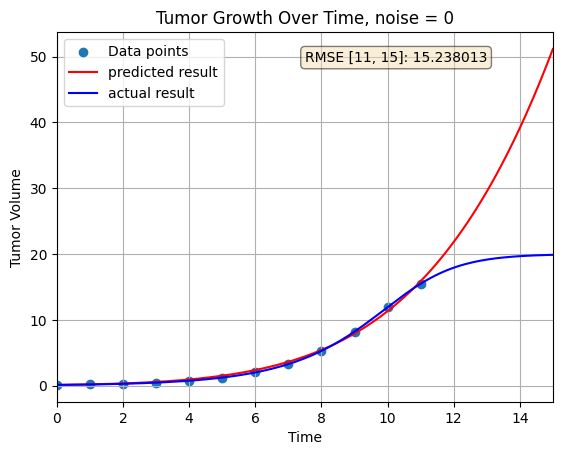

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import tumorData

maxSize = 20
rate = 0.5
initialSize = 0.1
tStart = 0
tEnd = 11
numPoints = 12
noise = 0

v = 2
C = (maxSize/initialSize) ** v - 1

Vol, t = tumorData.tumor_data(maxSize, rate, initialSize, tStart, tEnd, numPoints, noise, 'L')

Vol = Vol.flatten()
t = t.flatten()

print(f"Number of data points: {len(t)}")
print(f"t range: {t[0]:.2f} to {t[-1]:.2f}")

plt.figure(1)
plt.scatter(t, Vol, label='Data points')
plt.xlabel('Time')
plt.ylabel('Tumor Volume')
plt.title(f'Tumor Growth Over Time, noise = {noise}')
plt.grid(True)

def residual_function(p, t, Vol, initialSize):
    predicted = p[0] * np.exp(np.log(initialSize / p[0]) * np.exp(-p[1] * t))
    return (predicted - Vol).flatten()

p0 = [1, 1]

result = least_squares(
    residual_function, 
    p0, 
    method='lm',
    args=(t, Vol, initialSize),
    verbose=2
)

soln = result.x

print(f'Parameters: maxSize = {soln[0]:.4f}, rate = {soln[1]:.4f}')

predicted_curve = lambda t: soln[0] * np.exp(np.log(initialSize / soln[0]) * np.exp(-soln[1] * t))
actual_curve = lambda t: maxSize / (1 + C * np.exp(-rate * v * t)) ** (1 / v)

t_max = 15
t_plot_full = np.linspace(tStart, t_max, 200)
plt.plot(t_plot_full, predicted_curve(t_plot_full), 'r', label='predicted result')
plt.plot(t_plot_full, actual_curve(t_plot_full), 'b', label='actual result')

t_rmse = np.linspace(tEnd, t_max, 200)

predicted_values = predicted_curve(t_rmse)
actual_values = actual_curve(t_rmse)

rmse = np.sqrt(np.mean((predicted_values - actual_values)**2))

print(f'RMSE between predicted and actual curves in [{tEnd}, {t_max}]: {rmse:.6f}')

plt.text(0.5, 0.95, f'RMSE [{tEnd}, {t_max}]: {rmse:.6f}', 
         transform=plt.gca().transAxes, 
         fontsize=10, 
         verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.xlim(0, t_max)
plt.legend()
plt.show()

Code for Table 1: Phase-space candidates against true Gompertz

In [1]:
import SR_Wrapper
import csv
import os
import numpy as np
import sympy as sp
from itertools import combinations
from scipy.integrate import solve_ivp
import tumorData
import auxilary_func

# ---------------------------------------------------------------------------
# Settings
# ---------------------------------------------------------------------------
# Data generation: true law dV/dt = rate * V * log(maxSize / V)
maxSize = 20.0                  # carrying capacity K
rate = 0.5                      # growth rate a
initialSize = 0.1               # initial volume V(tStart)
tStart = 0.0                    # first sampling time
tEnd = 15.0                     # last sampling time
noise = 0.08                    # relative noise level (0.08 = 8%)
style = "G"                     # growth law used by tumorData ("G" = Gompertz)
numPoints = 6                   # data points per trial
# Random seeds
pysr_seed = 77                  # PySR random_state, the same for every trial
data_seed = 47                  # data seed of the first trial; trial i uses data_seed + i
# Spline k value
k = 5                           # min_k passed to the spline; the degree used is min(k, numPoints - 1)
# Trials and output
num_trials = 30                 # number of trials
results_dir = "refit_results"   # folder for the CSV files
noise_pct = f"{noise * 100:g}"  # noise as a percentage for file names (0.08 -> "8")
# Trajectory RMSE (real-space fit to the tumorData points)
use_observed_v0 = False         # trajectory start: False -> V(tStart) = initialSize, as in truth_real;
                                # True -> the first noisy data point

# Truth ODE, x0 is equivalent to V
truth_ode = f"{rate}*x0*log({maxSize}/x0)"
# Truth real-space law
truth_real = f"{maxSize}*exp(log({initialSize/maxSize})*exp(-{rate}*t))"

# ---------------------------------------------------------------------------
# Global variables, updated by trial()
# ---------------------------------------------------------------------------
# Phase-space RMSE values pooled over all trials
rmse_true_gompertz = np.array([])                 # true Gompertz law, one value per completed trial
rmse_all_candidates = np.array([])                # every PySR candidate of every completed trial

# Lowest-RMSE pick: the candidate with the lowest phase-space RMSE
num_lowest_rmse_pick_gompertz = 0                 # trials where it is Gompertz
num_lowest_rmse_pick_gompertz_or_reducible = 0    # trials where it is Gompertz or Gompertz-reducible
num_lowest_rmse_pick_beats_truth = 0              # trials where its phase-space RMSE is lower than the true law's
num_gompertz_best_overall = 0                     # trials where the lowest RMSE overall (true law included)
                                                  # belongs to a Gompertz law

# PySR default pick: PySR's own complexity-aware model selection
num_default_pick_gompertz = 0                     # trials where it is Gompertz
num_default_pick_gompertz_or_reducible = 0        # trials where it is Gompertz or Gompertz-reducible
num_default_pick_beats_truth = 0                  # trials where its phase-space RMSE is lower than the true law's

# Trajectory RMSE: fit of the integrated law to the real-space tumorData points (inf if the trajectory
# does not exist over the whole time span, nan if the PySR default pick is unavailable)
trajectory_rmse_true_gompertz = np.array([])      # true Gompertz law, one value per completed trial
trajectory_rmse_lowest_rmse_pick = np.array([])   # lowest-RMSE pick, one value per completed trial
trajectory_rmse_default_pick = np.array([])       # PySR default pick, one value per completed trial
num_lowest_rmse_pick_beats_truth_trajectory = 0   # trials where the lowest-RMSE pick has lower trajectory RMSE
                                                  # than the true law
num_default_pick_beats_truth_trajectory = 0       # trials where the PySR default pick has lower trajectory RMSE
                                                  # than the true law

# All candidates of a trial
num_trials_any_gompertz = 0                       # trials with at least one Gompertz candidate
num_trials_any_gompertz_or_reducible = 0          # trials with at least one Gompertz or Gompertz-reducible candidate

# Trial bookkeeping
num_trials_skipped = 0                            # trials excluded because the true law's RMSE was not finite
num_trials_points_removed = 0                     # trials whose spline output had V <= 0 points (removed)
trial_counter = 0                                 # loop counter; trial i uses data seed data_seed + i
summary_rows = []                                 # one row per trial for the summary CSV


# ---------------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------------
x0 = sp.Symbol("x0")            # phase-space variable (V)
u = sp.Symbol("u", real=True)   # log-volume, V = exp(u); used by the Gompertz-family test

# PySR operator names that SymPy does not know natively.
# Add entries here if your wrapper uses other custom operators.
PYSR_TO_SYMPY = {
    "x0": x0,
    "square": lambda a: a**2,
    "cube": lambda a: a**3,
    "neg": lambda a: -a,
    "inv": lambda a: 1 / a,
    "log10": lambda a: sp.log(a, 10),
    "log2": lambda a: sp.log(a, 2),
    "log1p": lambda a: sp.log(1 + a),
}


def to_sympy(equation):
    """Parse a PySR equation string (or SymPy expression) into a SymPy expression in x0.
    Returns None and prints a warning if parsing fails."""
    try:
        expr = sp.sympify(str(equation), locals=PYSR_TO_SYMPY)   # Julia '^' is converted to '**'
    except Exception as err:
        print(f"  Warning: could not parse '{equation}' ({err})")
        return None
    if not expr.free_symbols <= {x0}:
        print(f"  Warning: '{equation}' depends on variables other than x0")
        return None
    return expr


def phase_space_rmse(expr, V_smooth, dV_smooth):
    """RMSE between f(V_smooth) and dV_smooth for the ODE dV/dt = f(V).
    Unparseable, complex-valued or non-finite candidates get RMSE = inf so they can never be selected."""
    V = np.ravel(V_smooth).astype(float)
    dV = np.ravel(dV_smooth).astype(float)
    if expr is None or V.size == 0:
        return np.inf
    try:
        f = sp.lambdify(x0, expr, modules="numpy")
        with np.errstate(all="ignore"):
            pred = np.broadcast_to(np.asarray(f(V)), V.shape)   # constant laws -> full-length array
            if np.iscomplexobj(pred):
                return np.inf
            rmse = np.sqrt(np.mean((pred - dV) ** 2))
    except Exception:
        return np.inf
    return float(rmse) if np.isfinite(rmse) else np.inf


def simulate_trajectory(expr, t_eval, V0, t0):
    """Solve dV/dt = f(V) from V(t0) = V0 and return V at t_eval, or None if the solution does not exist
    over the whole time span (non-finite or complex growth rate, blow-up beyond 1e6, solver failure)."""
    if expr is None:
        return None
    t_eval = np.ravel(t_eval).astype(float)
    try:
        f = sp.lambdify(x0, expr, modules="numpy")
    except Exception:
        return None
    calls = [0]

    def rhs(t, y):
        calls[0] += 1
        with np.errstate(all="ignore"):
            dv = f(y[0])
        if np.iscomplexobj(dv) or not np.isfinite(dv) or calls[0] > 100_000:
            raise FloatingPointError("trajectory undefined")
        return [float(dv)]

    def blow_up(t, y):
        return 1e6 - abs(y[0])
    blow_up.terminal = True
    try:
        sol = solve_ivp(rhs, (t0, t_eval[-1]), [V0], t_eval=t_eval, method="LSODA",
                        rtol=1e-8, atol=1e-10, events=blow_up)
    except Exception:
        return None
    if sol.status != 0 or sol.y.shape[1] != t_eval.size or not np.all(np.isfinite(sol.y)):
        return None
    return sol.y[0]


def trajectory_rmse(expr, t_data, V_data, V0, t0):
    """Real-space RMSE between the trajectory of dV/dt = f(V) and the tumorData points (inf if no trajectory)."""
    V_pred = simulate_trajectory(expr, t_data, V0, t0)
    return np.inf if V_pred is None else float(np.sqrt(np.mean((V_pred - np.ravel(V_data)) ** 2)))


U_TEST = np.log([0.5, 1.0, 2.0, 5.0, 10.0, 15.0, 19.0])   # test volumes (as log V) for the quick numeric screen


def is_gompertz_family(expr):
    """True if f(V) can be written as a*V*log(K/V) with a != 0 (equivalently c1*V + c2*V*log(V), c2 != 0).
    Substituting V = exp(u), this holds exactly when f/V is linear in u with a nonzero slope (slope = -a)."""
    if expr is None:
        return False
    try:
        h = sp.expand_log(expr.subs(x0, sp.exp(u)) / sp.exp(u), force=True)
        curvature = sp.diff(h, u, 2)
        # Quick numeric screen: clearly nonzero curvature at the test volumes rules the law out
        # without the slow symbolic simplification. Inconclusive cases fall through to the exact test.
        try:
            with np.errstate(all="ignore"):
                h_vals = np.broadcast_to(np.asarray(sp.lambdify(u, h, "numpy")(U_TEST)), U_TEST.shape)
                c_vals = np.broadcast_to(np.asarray(sp.lambdify(u, curvature, "numpy")(U_TEST)), U_TEST.shape)
            ok = np.isfinite(h_vals) & np.isfinite(c_vals)
            if ok.any() and np.max(np.abs(c_vals[ok])) > 1e-6 * (1 + np.max(np.abs(h_vals[ok]))):
                return False
        except Exception:
            pass
        # Exact symbolic test
        if not sp.simplify(curvature).is_zero:
            return False
        slope = sp.simplify(sp.diff(h, u))
        return bool(slope.is_number and slope != 0)   # use `slope < 0` to also require a > 0
    except Exception:
        return False


def gompertz_reduction(expr):
    """Expanded definition: the smallest set of numeric constants that, set to zero, makes expr Gompertz-family
    (e.g. a*x0*log(K/x0) + c with c = 0, or log(x0 - c) with c = 0).
    Returns (zeroed_constants, reduced_expr), with () for a law that is already Gompertz-family, or None."""
    if expr is None or not expr.has(sp.log):
        return None                     # zeroing constants cannot create the V*log(V) term
    if is_gompertz_family(expr):
        return (), expr
    consts = sorted(expr.atoms(sp.Float), key=lambda c: abs(float(c)))
    ks = sp.symbols(f"k0:{len(consts)}")
    h = sp.expand_log(expr.xreplace(dict(zip(consts, ks))).subs(x0, sp.exp(u)) / sp.exp(u), force=True)
    try:   # compile once with the constants as arguments, so each subset is a fast numeric check
        h_fun = sp.lambdify((u, *ks), h, "numpy")
        c_fun = sp.lambdify((u, *ks), sp.diff(h, u, 2), "numpy")
    except Exception:
        c_fun = None
    values = np.array([float(c) for c in consts])
    for size in range(1, len(consts) + 1):
        for subset in combinations(range(len(consts)), size):
            if c_fun is not None:
                vals = values.copy()
                vals[list(subset)] = 0.0
                try:
                    with np.errstate(all="ignore"):
                        hv = np.broadcast_to(np.asarray(h_fun(U_TEST, *vals)), U_TEST.shape)
                        cv = np.broadcast_to(np.asarray(c_fun(U_TEST, *vals)), U_TEST.shape)
                    ok = np.isfinite(hv) & np.isfinite(cv)
                    if not ok.any() or np.max(np.abs(cv[ok])) > 1e-6 * (1 + np.max(np.abs(hv[ok]))):
                        continue
                except Exception:
                    pass
            reduced = expr.xreplace({consts[i]: 0 for i in subset})
            if is_gompertz_family(reduced):           # exact confirmation
                return tuple(consts[i] for i in subset), reduced
    return None


def gompertz_status(reduction):
    """Three-way status from gompertz_reduction(): Gompertz, Gompertz-reducible or Not Gompertz."""
    if reduction is None:
        return "Not Gompertz"
    return "Gompertz" if not reduction[0] else "Gompertz-reducible"


def default_best_index(pysr):
    """Position of PySR's default pick (its model_selection rule) in get_all_expressions(), or None.
    get_all_expressions() iterates model.equations_ in order, so the row label gives the position."""
    try:
        return list(pysr.model.equations_.index).index(pysr.model.get_best().name)
    except Exception:
        return None


def write_run_csv(seed, all_expr, statuses, rmses, traj_rmses, rmse_true, traj_rmse_true, default_idx, lowest_rmse_idx):
    """One CSV per run: every candidate, then the true law and the IDs of both picks."""
    os.makedirs(results_dir, exist_ok=True)
    path = os.path.join(results_dir, f"run_points{numPoints}_dataseed{seed}_noise{noise_pct}_pysrseed{pysr_seed}.csv")
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["Candidate ID", "Complexity", "Expression", "Status", "Phase-space RMSE", "Trajectory RMSE"])
        for i, (info, status, rmse, traj) in enumerate(zip(all_expr, statuses, rmses, traj_rmses), start=1):
            w.writerow([i, info.get("complexity", ""), str(info["equation"]), status, float(rmse), float(traj)])
        w.writerow([])
        w.writerow(["True Gompertz expression", str(truth_expr)])
        w.writerow(["True Gompertz phase-space RMSE", float(rmse_true)])
        w.writerow(["True Gompertz trajectory RMSE", float(traj_rmse_true)])
        w.writerow(["Best candidate ID (PySR default)", default_idx + 1 if default_idx is not None else "N/A"])
        w.writerow(["Best candidate ID (lowest phase-space RMSE)", lowest_rmse_idx + 1])
    return path


truth_expr = to_sympy(truth_ode)   # SymPy form of the true law
assert is_gompertz_family(truth_expr), "Gompertz-family test does not recognise the true law"


def check_trajectory_integrator():
    """The integrated true law must reproduce the analytic real-space law truth_real."""
    t_check = np.linspace(tStart, tEnd, 50)
    analytic = sp.lambdify(sp.Symbol("t"), sp.sympify(truth_real), "numpy")(t_check)
    numeric = simulate_trajectory(truth_expr, t_check, initialSize, tStart)
    assert numeric is not None and np.allclose(numeric, analytic, rtol=1e-5, atol=1e-6), \
        "trajectory integrator does not reproduce truth_real"


check_trajectory_integrator()


def trial(data_seed, pysr_seed):
    # trial() updates these module-level variables, so they must be declared global
    global rmse_true_gompertz, rmse_all_candidates, \
        num_lowest_rmse_pick_gompertz, num_lowest_rmse_pick_gompertz_or_reducible, \
        num_lowest_rmse_pick_beats_truth, num_gompertz_best_overall, \
        num_default_pick_gompertz, num_default_pick_gompertz_or_reducible, num_default_pick_beats_truth, \
        trajectory_rmse_true_gompertz, trajectory_rmse_lowest_rmse_pick, trajectory_rmse_default_pick, \
        num_lowest_rmse_pick_beats_truth_trajectory, num_default_pick_beats_truth_trajectory, \
        num_trials_any_gompertz, num_trials_any_gompertz_or_reducible, \
        num_trials_skipped, num_trials_points_removed

    # Generate test data
    V, t = tumorData.tumor_data(maxSize, rate, initialSize, tStart, tEnd, numPoints, noise, style, sd=data_seed)

    # Trajectory RMSE of real Gompertz: integrate each law from the same start and compare with the data points V
    traj_t0, traj_V0 = (np.ravel(t)[0], np.ravel(V)[0]) if use_observed_v0 else (tStart, initialSize)
    traj_rmse_true = trajectory_rmse(truth_expr, t, V, traj_V0, traj_t0)

    # Spline fit - generate phase space data
    V_smooth, dV_smooth = auxilary_func.fit_relationship_spline(t, V, plot=False, min_k=k)

    # Remove unreal spline points with V <= 0 (the true law and log(V) are undefined there).
    # The remaining points are used both for the PySR fit and for every RMSE.
    V_smooth, dV_smooth = np.asarray(V_smooth), np.asarray(dV_smooth)
    keep = np.ravel(V_smooth) > 0
    V_smooth, dV_smooth = V_smooth[keep], dV_smooth[keep]    # boolean mask on the first axis keeps the shape

    # Phase-space RMSE of real Gompertz
    rmse_true = phase_space_rmse(truth_expr, V_smooth, dV_smooth)
    if not np.isfinite(rmse_true):
        # Never let a non-finite truth RMSE into the comparisons: any candidate would "beat" it automatically
        print(f"data_seed={data_seed}: skipped, true Gompertz RMSE is not finite "
              f"(points with V > 0: {keep.sum()}/{keep.size})")
        num_trials_skipped += 1
        summary_rows.append([data_seed, rmse_true, traj_rmse_true, "", "Trial skipped", "", "",
                             "", "Trial skipped", "", ""])
        return
    if not keep.all():
        num_trials_points_removed += 1

    # Add to global arrays
    rmse_true_gompertz = np.append(rmse_true_gompertz, rmse_true)
    trajectory_rmse_true_gompertz = np.append(trajectory_rmse_true_gompertz, traj_rmse_true)

    # PySR law generation (V > 0 points only)
    pysr = SR_Wrapper.PySRWrapper(random_state=pysr_seed)
    pysr.fit(V_smooth, dV_smooth)

    # Extract all candidates
    all_expr = pysr.get_all_expressions()
    # Array to store RMSE information of every candidate
    rmse_trial = np.full(len(all_expr), np.inf)   # np.array(n) would create a 0-d array holding n
    traj_rmse_trial = np.full(len(all_expr), np.inf)   # trajectory RMSE of every candidate
    reductions, statuses = [], []                 # Gompertz test results, same order as rmse_trial
    for i, expr_info in enumerate(all_expr):
        expr = expr_info['equation']
        # Phase-space RMSE of every equation
        sym_expr = to_sympy(expr)
        rmse = phase_space_rmse(sym_expr, V_smooth, dV_smooth)
        # Trajectory RMSE of every equation
        traj_rmse_trial[i] = trajectory_rmse(sym_expr, t, V, traj_V0, traj_t0)
        # Status of every equation: Gompertz, Gompertz-reducible or Not Gompertz
        reductions.append(gompertz_reduction(sym_expr))
        statuses.append(gompertz_status(reductions[-1]))

        # Store RMSE in both the local and global storage
        rmse_trial[i] = rmse
        rmse_all_candidates = np.append(rmse_all_candidates, rmse)

    # Select best result based on phase-space RMSE (the lowest-RMSE pick)
    lowest_rmse_idx = int(np.argmin(rmse_trial))
    lowest_rmse = rmse_trial[lowest_rmse_idx]

    # PySR's default pick (its 'best' model selection: highest score among laws within 1.5x of the lowest loss)
    default_idx = default_best_index(pysr)
    if default_idx is not None:
        default_expr = all_expr[default_idx]['equation']
        default_status, default_rmse = statuses[default_idx], rmse_trial[default_idx]
        default_traj_rmse = traj_rmse_trial[default_idx]
    else:   # position unknown: evaluate PySR's pick directly
        try:
            default_expr = pysr.get_best_expression()
            default_sym = to_sympy(default_expr)
            default_status = gompertz_status(gompertz_reduction(default_sym))
            default_rmse = phase_space_rmse(default_sym, V_smooth, dV_smooth)
            default_traj_rmse = trajectory_rmse(default_sym, t, V, traj_V0, traj_t0)
        except Exception:
            default_expr, default_status, default_rmse, default_traj_rmse = "N/A", "N/A", np.nan, np.nan
    lowest_traj_rmse = traj_rmse_trial[lowest_rmse_idx]

    # Save this run: every candidate, the true law, and the IDs of both picks
    write_run_csv(data_seed, all_expr, statuses, rmse_trial, traj_rmse_trial, rmse_true, traj_rmse_true,
                  default_idx, lowest_rmse_idx)

    # Check if the lowest-RMSE pick is in Gompertz family
    # If so, add 1 to num_lowest_rmse_pick_gompertz
    lowest_rmse_is_gompertz = statuses[lowest_rmse_idx] == "Gompertz"
    if lowest_rmse_is_gompertz:
        num_lowest_rmse_pick_gompertz += 1

    # Check if any candidate, not only the picks, is in Gompertz family
    # If so, add 1 to num_trials_any_gompertz
    if "Gompertz" in statuses:
        num_trials_any_gompertz += 1

    # Expanded definition: also count laws that become Gompertz-family when some constants are set to zero
    # If so, add 1 to num_lowest_rmse_pick_gompertz_or_reducible / num_trials_any_gompertz_or_reducible
    gompertz_like = ("Gompertz", "Gompertz-reducible")
    if statuses[lowest_rmse_idx] in gompertz_like:
        num_lowest_rmse_pick_gompertz_or_reducible += 1
    if any(st in gompertz_like for st in statuses):
        num_trials_any_gompertz_or_reducible += 1

    # Check the PySR default pick: Gompertz? Gompertz or Gompertz-reducible? Lower RMSE than true Gompertz?
    # If so, add 1 to num_default_pick_gompertz / num_default_pick_gompertz_or_reducible / num_default_pick_beats_truth
    if default_status == "Gompertz":
        num_default_pick_gompertz += 1
    if default_status in gompertz_like:
        num_default_pick_gompertz_or_reducible += 1
    default_beats_truth = default_rmse < rmse_true    # False when the default pick is N/A (RMSE = nan)
    if default_beats_truth:
        num_default_pick_beats_truth += 1

    # Check if the lowest-RMSE pick has lower phase-space RMSE than true Gompertz
    # If so, add 1 to num_lowest_rmse_pick_beats_truth
    lowest_rmse_beats_truth = lowest_rmse < rmse_true
    if lowest_rmse_beats_truth:
        num_lowest_rmse_pick_beats_truth += 1

    # Check if Gompertz law, no matter the true law or the lowest-RMSE pick, has the lowest phase space RMSE among all candidates
    # If so, add 1 to num_gompertz_best_overall
    # The overall winner is the true law unless the lowest-RMSE pick beats it; then that pick must be Gompertz.
    if not lowest_rmse_beats_truth or lowest_rmse_is_gompertz:
        num_gompertz_best_overall += 1

    # Trajectory RMSE: compare both picks with the true law on the real-space data points
    # If a pick has the lower trajectory RMSE, add 1 to num_lowest_rmse_pick_beats_truth_trajectory /
    # num_default_pick_beats_truth_trajectory (inf = no trajectory and nan = unavailable never count)
    trajectory_rmse_lowest_rmse_pick = np.append(trajectory_rmse_lowest_rmse_pick, lowest_traj_rmse)
    trajectory_rmse_default_pick = np.append(trajectory_rmse_default_pick, default_traj_rmse)
    if lowest_traj_rmse < traj_rmse_true:
        num_lowest_rmse_pick_beats_truth_trajectory += 1
    if default_traj_rmse < traj_rmse_true:
        num_default_pick_beats_truth_trajectory += 1

    # Row for the summary CSV
    summary_rows.append([data_seed, float(rmse_true), float(traj_rmse_true),
                         str(default_expr), default_status, float(default_rmse), float(default_traj_rmse),
                         str(all_expr[lowest_rmse_idx]['equation']), statuses[lowest_rmse_idx], float(lowest_rmse),
                         float(lowest_traj_rmse)])

    print(f"data_seed={data_seed}: lowest-RMSE pick = {all_expr[lowest_rmse_idx]['equation']} | "
          f"RMSE = {lowest_rmse:.4g} (true Gompertz {rmse_true:.4g}) | {statuses[lowest_rmse_idx]} | "
          f"points used: {keep.sum()}/{keep.size}")
    print(f"    trajectory RMSE: lowest-RMSE pick {lowest_traj_rmse:.4g}, PySR default pick {default_traj_rmse:.4g}, "
          f"true Gompertz {traj_rmse_true:.4g}")
    gompertz_idx = next((i for i, st in enumerate(statuses) if st == "Gompertz"), None)
    if gompertz_idx is not None and not lowest_rmse_is_gompertz:
        print(f"    Gompertz-family candidate (not selected): {all_expr[gompertz_idx]['equation']} | "
              f"RMSE = {rmse_trial[gompertz_idx]:.4g}")
    if statuses[lowest_rmse_idx] == "Gompertz-reducible":
        zeroed, reduced = reductions[lowest_rmse_idx]
        print(f"    lowest-RMSE pick is Gompertz-reducible: set {[float(c) for c in zeroed]} to 0 -> {reduced}")
    print(f"    PySR default pick (ID {default_idx + 1 if default_idx is not None else 'N/A'}): {default_expr} | "
          f"RMSE = {default_rmse:.4g} | {default_status} | lower RMSE than true Gompertz: {default_beats_truth}")

while trial_counter < num_trials:
    trial(data_seed + trial_counter, pysr_seed)
    trial_counter = trial_counter + 1

# Trials that ran PySR (denominator for the counts below)
num_trials_completed = trial_counter - num_trials_skipped
n = num_trials_completed


def median_of(values):
    """Median over trials; nan (pick unavailable) is ignored, inf (no trajectory) counts as the worst value."""
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    return float(np.median(values)) if values.size else np.nan


def report(label, value):
    """Print one line of the end-of-run summary."""
    print(f"{label:<66}{value}")


# Medians of the trajectory RMSE over completed trials
median_trajectory_rmse_true_gompertz = median_of(trajectory_rmse_true_gompertz)
median_trajectory_rmse_lowest_rmse_pick = median_of(trajectory_rmse_lowest_rmse_pick)
median_trajectory_rmse_default_pick = median_of(trajectory_rmse_default_pick)

print()
report("Completed trials:", f"{n}/{trial_counter} (skipped {num_trials_skipped})")
report("Trials with V <= 0 points removed:", f"{num_trials_points_removed}/{n}")
# Lowest-RMSE pick
report("Lowest-RMSE pick is Gompertz:", f"{num_lowest_rmse_pick_gompertz}/{n}")
report("Lowest-RMSE pick is Gompertz or Gompertz-reducible:", f"{num_lowest_rmse_pick_gompertz_or_reducible}/{n}")
report("Lowest-RMSE pick has lower phase-space RMSE than true Gompertz:", f"{num_lowest_rmse_pick_beats_truth}/{n}")
report("Gompertz law has the lowest phase-space RMSE overall:", f"{num_gompertz_best_overall}/{n}")
# PySR default pick
report("PySR default pick is Gompertz:", f"{num_default_pick_gompertz}/{n}")
report("PySR default pick is Gompertz or Gompertz-reducible:", f"{num_default_pick_gompertz_or_reducible}/{n}")
report("PySR default pick has lower phase-space RMSE than true Gompertz:", f"{num_default_pick_beats_truth}/{n}")
# All candidates
report("Trials with any Gompertz candidate:", f"{num_trials_any_gompertz}/{n}")
report("Trials with any Gompertz or Gompertz-reducible candidate:", f"{num_trials_any_gompertz_or_reducible}/{n}")
# Pooled phase-space RMSE
report("Median phase-space RMSE, true Gompertz law:", f"{np.median(rmse_true_gompertz):.4g}")
report("Median phase-space RMSE, all PySR candidates:", f"{np.median(rmse_all_candidates):.4g}")
# Trajectory RMSE (real-space data points from tumorData)
report("Lowest-RMSE pick has lower trajectory RMSE than true Gompertz:", f"{num_lowest_rmse_pick_beats_truth_trajectory}/{n}")
report("PySR default pick has lower trajectory RMSE than true Gompertz:", f"{num_default_pick_beats_truth_trajectory}/{n}")
report("Median trajectory RMSE, true Gompertz law:", f"{median_trajectory_rmse_true_gompertz:.4g}")
report("Median trajectory RMSE, lowest-RMSE pick:", f"{median_trajectory_rmse_lowest_rmse_pick:.4g}")
report("Median trajectory RMSE, PySR default pick:", f"{median_trajectory_rmse_default_pick:.4g}")

# Summary CSV: one row per trial, then the medians of the trajectory RMSE
os.makedirs(results_dir, exist_ok=True)
summary_path = os.path.join(results_dir, f"summary_points{numPoints}_dataseeds{data_seed}-{data_seed + num_trials - 1}"
                                         f"_noise{noise_pct}_pysrseed{pysr_seed}.csv")
with open(summary_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.writer(f)
    writer.writerow(["Trial seed", "True Gompertz phase-space RMSE", "True Gompertz trajectory RMSE",
                     "Best PySR expression (default)", "Status of default best expression",
                     "Default best expression phase-space RMSE", "Default best expression trajectory RMSE",
                     "Expression with lowest phase-space RMSE", "Status of lowest-RMSE expression",
                     "Lowest phase-space RMSE value", "Lowest-RMSE expression trajectory RMSE"])
    writer.writerows(summary_rows)
    writer.writerow([])
    writer.writerow(["Median true Gompertz trajectory RMSE", median_trajectory_rmse_true_gompertz])
    writer.writerow(["Median lowest-RMSE pick trajectory RMSE", median_trajectory_rmse_lowest_rmse_pick])
    writer.writerow(["Median PySR default pick trajectory RMSE", median_trajectory_rmse_default_pick])
print(f"\nPer-run CSV files saved in '{results_dir}'; summary saved as '{summary_path}'")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
Compiling Julia backend...
[ Info: Started!



Expressions evaluated per second: 2.220e+05
Progress: 1308 / 31000 total iterations (4.219%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           6.183e+00  0.000e+00  y = 1.3483
5           6.183e+00  -0.000e+00  y = (x₀ + 1.3484) - x₀
6           4.509e+00  3.157e-01  y = (x₀ * -0.19646) - -4.4761
8           4.509e+00  -0.000e+00  y = (x₀ - (x₀ * 1.1965)) + 4.4761
11          4.242e+00  2.033e-02  y = (x₀ * -0.30955) + (log(x₀) + 3.7077)
13          4.111e+00  1.576e-02  y = (x₀ * -0.32599) + (log(x₀ - 0.10293) + 4.0012)
14          4.093e+00  4.384e-03  y = (x₀ * -0.32012) + log((x₀ * 49.912) - 5.2275)
16          4.091e+00  1.872e-04  y = log((x₀ * 50.229) - 5.2694) + ((x₀ - 0.33368) * -0.326...
                                      52)
17          4.075e+00  3.818e-03  y = ((log(

[ Info: Final population:
[ Info: Results saved to:


data_seed=47: lowest-RMSE pick = (x0 - 0.6635929)*(0.04875803*x0 - log(x0 - 0.104389265) + 1.8893443) + 2.6030302 | RMSE = 1.976 (true Gompertz 2.345) | Gompertz-reducible | points used: 182/200
    trajectory RMSE: lowest-RMSE pick inf, PySR default pick 2.153, true Gompertz 1.455
    lowest-RMSE pick is Gompertz-reducible: set [0.04875803, -0.104389265, -0.6635929, 2.6030302] to 0 -> x0*(1.8893443 - log(x0))
    PySR default pick (ID 3): 4.4760656 - 0.19645828*x0 | RMSE = 2.123 | Not Gompertz | lower RMSE than true Gompertz: True


...

data_seed=75: lowest-RMSE pick = -0.6251967*x0 + log(x0)*log(x0 + 4.3588285) + 3.7249913 | RMSE = 0.8169 (true Gompertz 1.2) | Not Gompertz | points used: 182/200
    trajectory RMSE: lowest-RMSE pick 2.327, PySR default pick 2.341, true Gompertz 1.142
    PySR default pick (ID 5): 3.9215808 - 0.0077834483*x0**2 | RMSE = 0.9783 | Not Gompertz | lower RMSE than true Gompertz: True


c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 2.340e+05
Progress: 1338 / 31000 total iterations (4.316%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.247e+00  0.000e+00  y = 1.2751
5           2.247e+00  1.043e-07  y = (x₀ + 1.2751) - x₀
6           1.299e+00  5.478e-01  y = log(20.413 - x₀)
8           1.278e+00  8.232e-03  y = log(20.689 - x₀) + -0.20864
9           1.201e+00  6.204e-02  y = x₀ * ((x₀ * -0.035371) + 0.6713)
11          1.025e+00  7.937e-02  y = (x₀ * ((x₀ * -0.024529) + 0.39242)) + 1.4877
13          1.025e+00  2.205e-06  y = ((x₀ + (0.39246 + (x₀ * -1.0245))) * x₀) + 1.4872
14          1.018e+00  6.755e-03  y = (log(x₀) + -2.9638) * ((x₀ - -0.37115) * -0.42678)
16          1.004e+00  6.785e-03  y = (x₀ * ((((x₀ * 0.00097107) + -0.055345) * x₀) + 0.6525...
            

[ Info: Final population:
[ Info: Results saved to:



Expressions evaluated per second: 2.330e+05
Progress: 30617 / 31000 total iterations (98.765%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           2.247e+00  0.000e+00  y = 1.2751
5           2.247e+00  1.490e-07  y = (x₀ + 1.2751) - x₀
6           1.299e+00  5.478e-01  y = log(20.413 - x₀)
8           1.278e+00  8.232e-03  y = log(20.688 - x₀) + -0.20847
9           1.201e+00  6.204e-02  y = x₀ * ((x₀ * -0.035371) + 0.6713)
11          1.025e+00  7.937e-02  y = (((x₀ * -0.024528) + 0.3924) * x₀) + 1.4877
13          1.025e+00  3.189e-06  y = (x₀ * (((x₀ * -1.0245) + 0.39226) + x₀)) + 1.4882
14          1.018e+00  6.753e-03  y = (x₀ - -0.37096) * ((log(x₀) * -0.4268) + 1.2649)
16          1.004e+00  6.785e-03  y = (x₀ * ((x₀ * ((x₀ * 0.00097115) + -0.055347)) + 0.6525...
             

Code for Table 5: PINN refit against Gompertz data fit for sparse (high noise), medium (moderate noise), and dense (little noise) data

`ftol` termination condition is satisfied.
Function evaluations 13, initial cost 1.3071e+03, final cost 2.8019e+00, first-order optimality 4.54e-07.
Parameters: maxSize = 20.2150, rate = 0.4959


c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\pysr\sr.py:2811: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(
[ Info: Started!



Expressions evaluated per second: 1.910e+05
Progress: 1145 / 31000 total iterations (3.694%)
════════════════════════════════════════════════════════════════════════════════════════════════════
───────────────────────────────────────────────────────────────────────────────────────────────────
Complexity  Loss       Score      Equation
1           1.177e+00  0.000e+00  y = 1.4299
5           1.177e+00  2.682e-07  y = (x₀ + 1.4299) - x₀
6           1.495e-02  4.366e+00  y = log(21.322 - x₀)
8           1.494e-02  2.783e-04  y = log(21.316 - x₀) + 0.0039786
9           1.483e-02  7.548e-03  y = log(21.327 - x₀) * 0.99373
11          1.091e-02  1.537e-01  y = (log(20.989 - x₀) * 0.87727) + 0.31168
12          1.073e-02  1.616e-02  y = log(32.833 - (x₀ * 1.5704)) * 0.84621
13          6.572e-03  4.905e-01  y = -0.17327 + ((x₀ * 0.020779) + log(21.055 - x₀))
14          3.450e-03  6.446e-01  y = ((x₀ * 0.010842) + 0.91732) * log(21.278 - x₀)
16          9.690e-04  6.349e-01  y = ((x₀ * 0.10

[ Info: Final population:
[ Info: Results saved to:


[2] Best expression after PINN refit: log(21.3213310241699 - x0)
[3] Best expression after PINN refit: log(21.3151721954346 - x0) + 0.0021848041915024
[4] Best expression after PINN refit: 0.991094168846347*log(21.3260860443115 - x0)
[5] Best expression after PINN refit: 0.84411594226118*log(20.9029598236084 - x0) + 0.389257496674979
[6] Best expression after PINN refit: 2.58574848262633*log(log(23.0331707000732 - x0))
[7] Best expression after PINN refit: 0.0214948058128357*x0 + log(21.0402164459229 - x0) - 0.179052620127289
[8] Best expression after PINN refit: (0.0107996881008148*x0 + 0.914736061409076)*log(21.2744941711426 - x0)
[9] Skipping — error: Parameter c1 is multiplied by other learnable parameter(s) outside logarithms: [c2].


c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\juliacall\__init__.py:61: UserWarning: torch was imported before juliacall. This may cause a segfault. To avoid this, import juliacall before importing torch. For updates, see https://github.com/pytorch/pytorch/issues/78829.
  warnings.warn(
c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\juliacall\__init__.py:61: UserWarning: torch was imported before juliacall. This may cause a segfault. To avoid this, import juliacall before importing torch. For updates, see https://github.com/pytorch/pytorch/issues/78829.
  warnings.warn(
c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmpysr\Lib\site-packages\juliacall\__init__.py:61: UserWarning: torch was imported before juliacall. This may cause a segfault. To avoid this, import juliacall before importing torch. For updates, see https://github.com/pytorch/pytorch/issues/78829.
  warnings.warn(
c:\Users\31593\Desktop\PythonProjects\MATH_Code\llmp

[10] Skipping — error: Parameter c1 is multiplied by other learnable parameter(s) outside logarithms: [c3, c4].
Median RMSE: 0.32499426452746727
LM RMSE: 0.21410839213147861
Number of PINN better than LM: 0 / 7
PINN refit success rate: 7/11 (63.6%)
Results saved to c:\Users\31593\Desktop\PythonProjects\MATH_Code\pinn_refit_results_N12_noise5_dataseed47_pysrseed77.csv


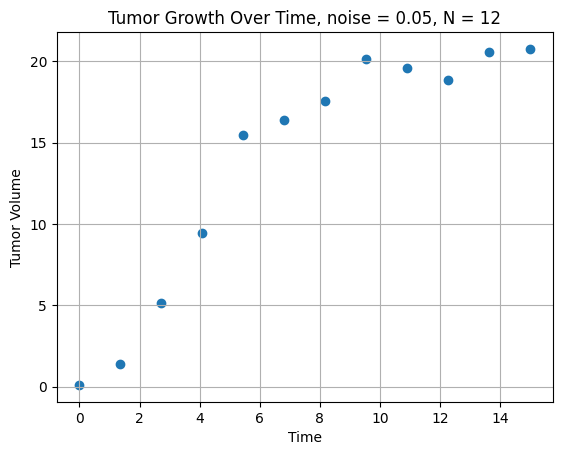

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import tumorData
import SR_Wrapper as wp
import auxilary_func as af
import sympy as sp

import csv
import multiprocessing
import numbers
import os

# worker lives in its own module so Windows spawn can import it cleanly
from worker import process_expression_worker


def drain_queue(q):
    """Return every message the worker put on the queue before it exited."""
    messages = []
    while not q.empty():
        messages.append(q.get())
    return messages


def is_valid_rmse(value):
    """af.ODE_rmse_forecast returns a float on success, but a string such as
    'Domain failure' or 'Unsolvable ODE' when the forecast can't be computed."""
    return isinstance(value, numbers.Real) and bool(np.isfinite(value))


if __name__ == '__main__':

    maxSize = 20
    rate = 0.5
    initialSize = 0.1
    tStart = 0
    tEnd = 15
    numPoints = 12
    noise = 0.05
    data_seed = 47   # seed for the noisy training data (tumor_data's default)
    pysr_seed = 77   # random_state passed to PySR

    # Noise is written as a percentage, e.g. noise = 0.01 -> "_noise1_"
    csv_filename = (
        f"pinn_refit_results_N{numPoints}_noise{noise * 100:g}"
        f"_dataseed{data_seed}_pysrseed{pysr_seed}.csv"
    )

    Vol, t = tumorData.tumor_data(
        maxSize, rate, initialSize, tStart, tEnd, numPoints, noise, 'G',
        sd=data_seed,
    )
    Vol = Vol.flatten()
    t = t.flatten()

    t_test_start = tEnd + 0.5
    t_test_end = t_test_start + 10
    Vol_test, t_test = tumorData.tumor_data(
        maxSize, rate, initialSize, t_test_start, t_test_end, numPoints, 0, 'G'
    )

    plt.figure(1)
    plt.scatter(t, Vol, label='Data points')
    plt.xlabel('Time')
    plt.ylabel('Tumor Volume')
    plt.title(f'Tumor Growth Over Time, noise = {noise}, N = {numPoints}')
    plt.grid(True)

    # ===================
    # LM refit
    # ===================

    def residual_function(p, t, Vol, initialSize):
        predicted = p[0] * np.exp(np.log(initialSize / p[0]) * np.exp(-p[1] * t))
        return (predicted - Vol).flatten()

    p0 = [1, 1]
    result = least_squares(
        residual_function, p0, method='lm',
        args=(t, Vol, initialSize), verbose=2
    )
    soln = result.x

    print(f'Parameters: maxSize = {soln[0]:.4f}, rate = {soln[1]:.4f}')
    lm_ode = f"{soln[1]}*x0*log({soln[0]}/x0)"
    rmse_lm = af.ODE_rmse_forecast(lm_ode, Vol_test, t_test, [0.1, 0])
    lm_ok = is_valid_rmse(rmse_lm)
    if not lm_ok:
        print(f"Warning: LM forecast failed ({rmse_lm}); PINN-vs-LM comparison skipped.")

    # ===================
    # PINN refit
    # ===================

    # Note on min_k: spline degree. It controls the curvature of the spline.
    # Ranges from 3 (cubic) to 5 (quintic)
    # In higher noise cases, lower k value prevent spline overfitting.
    # In low noise cases (like 1% noise), lower k will underfit.
    # Therefore min_k = 5 will give better results for N=40, noise=0.01 than min_k = 3.
    # For all other cases, min_k is set to 3.
    V_smooth, dV_smooth = af.fit_relationship_spline(t, Vol, plot=False, min_k=3)

    sr_wrapper = wp.PySRWrapper(random_state=pysr_seed)
    sr_wrapper.fit(V_smooth, dV_smooth)
    all_expr = sr_wrapper.get_all_expressions()

    print(f"Total number of expressions: {len(all_expr)}")

    # ===================
    # Timed for loop (+ CSV export)
    # ===================

    TIMEOUT_SECONDS = 60

    num_success = 0
    rmse_all = []
    num_better = 0

    with open(csv_filename, "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow([
            "Candidate ID",
            "PySR candidate expression",
            "Filter (Pass/Fail)",
            "Refitted PINN expression",
            "Forecast RMSE",
        ])

        for i, expr_dict in enumerate(all_expr):
            # SimpleQueue writes straight to the pipe (no feeder thread), so a
            # message sent just before a crash or timeout is not lost.
            result_queue = multiprocessing.SimpleQueue()

            p = multiprocessing.Process(
                target=process_expression_worker,
                args=(
                    expr_dict, Vol, t, Vol_test, t_test,
                    initialSize, tStart, tEnd, result_queue,
                )
            )
            p.start()
            p.join(timeout=TIMEOUT_SECONDS)

            timed_out = p.is_alive()
            if timed_out:
                p.terminate()
                p.join()

            # The worker sends the filter verdict as soon as it has it, then a
            # final message, so the verdict survives a later timeout/crash.
            messages = drain_queue(result_queue)
            filter_msgs = [m for m in messages if m["status"] == "filter_result"]
            final_msgs = [m for m in messages if m["status"] != "filter_result"]
            passed_filter = bool(filter_msgs) and filter_msgs[0]["filter_status"] == "Pass"
            res = final_msgs[0] if final_msgs else None

            # Both PINN columns stay "N/A" unless the refit fully succeeds
            pinn_expr_cell = "N/A"
            rmse_cell = "N/A"

            if timed_out:
                print(f"[{i}] Skipping — exceeded {TIMEOUT_SECONDS}s timeout")
            elif res is None:
                print(f"[{i}] Skipping — process ended with no result (crashed)")
            elif res["status"] == "filtered":
                pass
            elif res["status"] == "error":
                print(f"[{i}] Skipping — error: {res['reason']}")
            elif not is_valid_rmse(res["rmse_ode"]):
                # PINN gave an expression, but its forecast couldn't be computed
                print(f"[{i}] Skipping — forecast failed ({res['rmse_ode']}) "
                      f"for PINN refit {res['pinn_expr_str']}")
            else:
                num_success += 1
                print(f"[{i}] Best expression after PINN refit: {res['pinn_expr_str']}")
                rmse_all.append(res["rmse_ode"])
                if lm_ok and res["rmse_ode"] < rmse_lm:
                    num_better += 1
                pinn_expr_cell = res["pinn_expr_str"]
                rmse_cell = res["rmse_ode"]

            writer.writerow([
                i,
                str(expr_dict["equation"]),
                "Pass" if passed_filter else "Fail",
                pinn_expr_cell,
                rmse_cell,
            ])
            csv_file.flush()  # rows so far survive if the run is interrupted

        # ---------- Summary ----------
        total = len(all_expr)
        success_rate = f"{num_success}/{total}"
        if total:
            # The percentage also stops Excel from reading "5/23" as a date
            success_rate += f" ({num_success / total:.1%})"
        median_rmse = float(np.median(rmse_all)) if rmse_all else "N/A"

        writer.writerow([])
        writer.writerow(["Summary"])
        writer.writerow(["LM refitted expression", lm_ode])
        writer.writerow(["LM forecast RMSE", rmse_lm])
        writer.writerow(["PINN refit success rate (successful refits / total expressions)",
                         success_rate])
        writer.writerow(["Median forecast RMSE of PINN refits", median_rmse])
        writer.writerow(["PINN refits with lower forecast RMSE than LM",
                         num_better if lm_ok else "N/A"])

    if rmse_all:
        print(f"Median RMSE: {np.median(rmse_all)}")
    else:
        print("No successful PINN fits.")
    print(f"LM RMSE: {rmse_lm}")
    print(f"Number of PINN better than LM: {num_better} / {num_success}")
    print(f"PINN refit success rate: {success_rate}")
    print(f"Results saved to {os.path.abspath(csv_filename)}")